<a href="https://colab.research.google.com/github/Nithya-2-2/MLImaging/blob/practice/Week4_Cat_Dolphin_KNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CAT vs DOLPHIN Classification using PCA and k-NN



---



# Aim

The aim is to classify the images of cats and dolphin using Principal Component Analysis (PCA) for dimensionality reduction and K-Nearest Neighbours (K-NN) for classification.

Objectives:


1. Load and preprocess the image data
2. Convert images to feature vectors
3. Reduce dimensionality using PCA
4. Determine the optimal number of principal components
5. Find the best k value for k-NN
6. Evaluate classifier performance using multiple metrics





---



1. Import Libraries

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import glob
import os

from skimage import io
from skimage.transform import resize
from skimage.color import rgb2gray

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score
)

2. Loading the Dataset

In [ ]:


from google.colab import drive, files
drive.mount('/content/drive') # mount your google colab file
SIZE = 128  # Resize all images to this size

#Capture training data and labels into respective lists
images = []
labels = []

# Read in the images
for directory_path in glob.glob("/content/drive/MyDrive/MLImaging/ML_IPData/*"):
    label = directory_path.split("/")[-1]
    print(label)
    for file in glob.glob(os.path.join(directory_path, "*.jpg")):
        img = io.imread(file)
        if len(img.shape) == 3:
          img = rgb2gray(img)
        img = resize(img, (SIZE, SIZE))
        images.append(img.flatten())
        labels.append(label)




Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Dolphin
Cat


3. Data Exploration

In [ ]:
images = np.array(images)
print(images.shape)
print(len(labels))

(1684, 16384)
1684


In [ ]:
unique, counts = np.unique(labels, return_counts = True)

for c,n in zip(unique, counts):
  print(c,n)



Cat 869
Dolphin 815


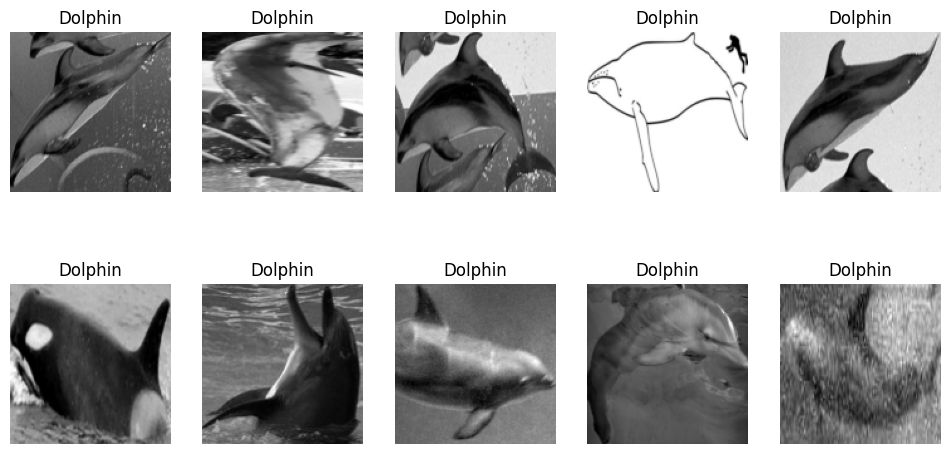

In [ ]:
fig,ax = plt.subplots(2,5,figsize=(12,6))

for i in range(10):
  ax.flat[i].imshow(images[i].reshape(SIZE,SIZE),cmap='gray')
  ax.flat[i].set_title(labels[i])
  ax.flat[i].axis('off')


plt.show()


In [ ]:
encoder = LabelEncoder()

y = encoder.fit_transform(labels)
print(encoder.classes_)

['Cat' 'Dolphin']


4. Splitting Train and Test dataset

In [ ]:
X_train_initial, X_test_initial, y_train, y_test = train_test_split(
    images,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [ ]:
print(X_train_initial.shape)
print(X_test_initial.shape)

(1347, 16384)
(337, 16384)


Trying to standardize the data to improve accuracy

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train= scaler.fit_transform(X_train_initial)

X_test = scaler.transform(X_test_initial)

5. PCA Analysis

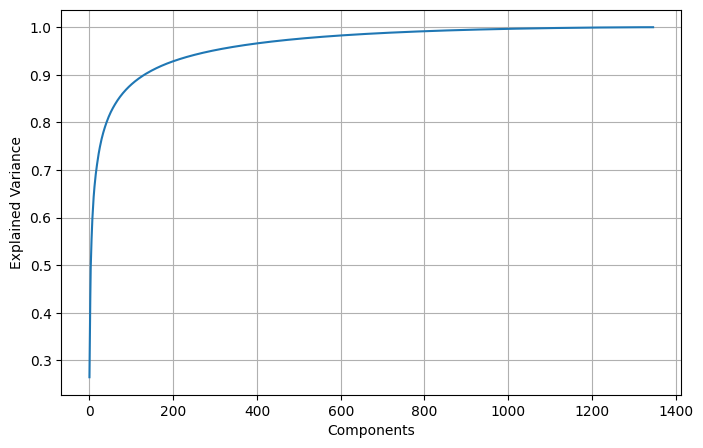

In [ ]:
#Explained Variance
pca_full = PCA()

pca_full.fit(X_train)

cum_var = np.cumsum(
    pca_full.explained_variance_ratio_
)

plt.figure(figsize=(8,5))
plt.plot(cum_var)
plt.xlabel("Components")
plt.ylabel("Explained Variance")
plt.grid()

In [ ]:
#Number of components required

for threshold in [0.8,0.85,0.9,0.95]:
  n = np.argmax(cum_var >=threshold)+1
  print(f'{threshold*100}% variance ={n} componnents')

80.0% variance =42 componnents
85.0% variance =71 componnents
90.0% variance =132 componnents
95.0% variance =292 componnents



*   5a. Eigenfaces / Eigenimages



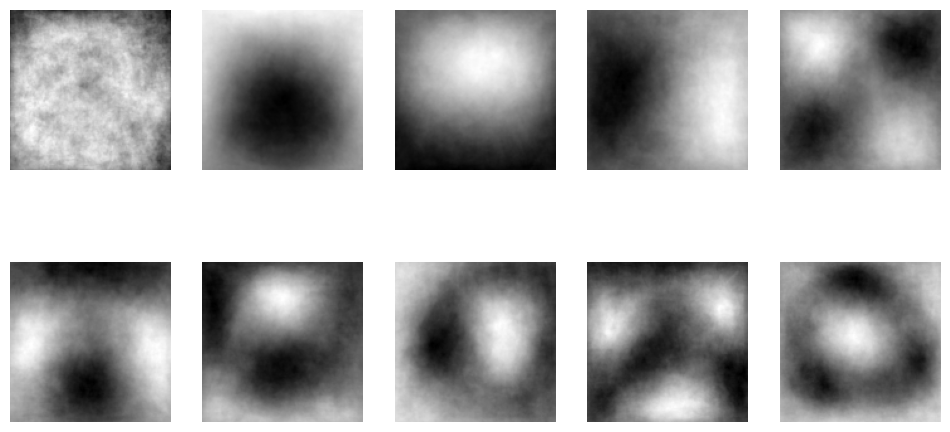

In [ ]:
pca = PCA(n_components=100)

pca.fit(X_train)

fig,ax = plt.subplots(2,5, figsize = (12,6))

for i in range(10):
  ax.flat[i].imshow(
      pca.components_[i].reshape(SIZE,SIZE),
      cmap='gray'
  )

  ax.flat[i].axis('off')


plt.show()



*   5b. Reconstruction of the images



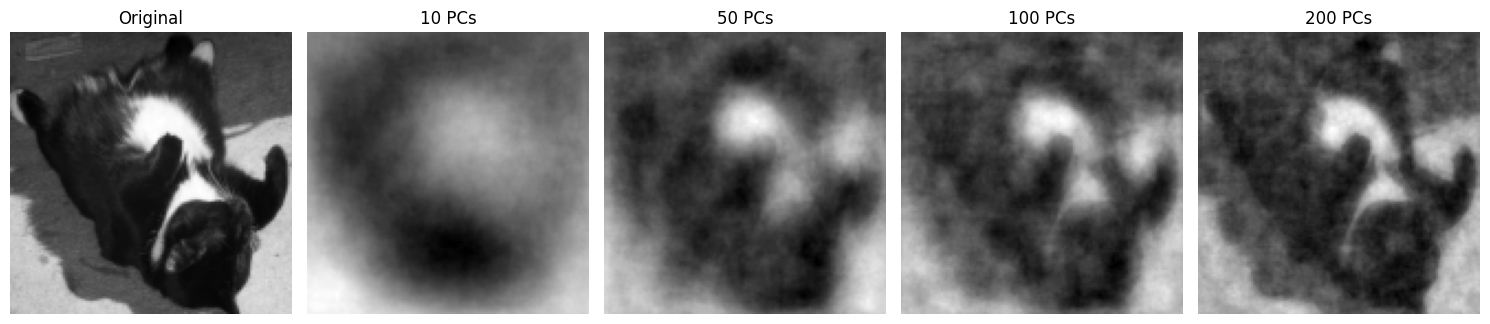

In [ ]:
components = [10,50,100,200]

sample = X_train[0]

figure, axes = plt.subplots(1,5,figsize=(15,4))

axes[0].imshow(sample.reshape(128,128), cmap='gray')
axes[0].set_title("Original")
axes[0].axis('off')

for a,b in enumerate(components):
  pca = PCA(n_components=b)
  pca.fit(X_train)

  transformed = pca.transform(sample.reshape(1,-1))
  reconstructed = pca.inverse_transform(transformed)

  axes[a+1].imshow(
      reconstructed.reshape(128,128),
      cmap='gray'
  )

  axes[a+1].set_title(f"{b} PCs")
  axes[a+1].axis('off')


plt.tight_layout()
plt.show()


# 5. PCA Feature Comparison

In [ ]:
pca_sizes = [42,71,132,291]

results = []

for n in pca_sizes:
  pca = PCA(n_components=n)

  X_train_pca = pca.fit_transform(X_train)
  X_test_pca = pca.transform(X_test)

  #KNN
  knn = KNeighborsClassifier(n_neighbors=5)
  knn.fit(X_train_pca,y_train)

  y_pred = knn.predict(X_test_pca)

  #Metrics
  acc = accuracy_score(y_test,y_pred)
  prec = precision_score(y_test,y_pred)
  rec = recall_score(y_test,y_pred)
  f1 = f1_score(y_test,y_pred)

  results.append([n,acc,prec,rec,f1])


results_df = pd.DataFrame(
    results,
    columns=['PCs','Accuracy','Precision','Recall','F1 Score']
)

print(results_df)

   PCs  Accuracy  Precision    Recall  F1 Score
0   42  0.587537   0.545455  0.883436  0.674473
1   71  0.596439   0.549815  0.914110  0.686636
2  132  0.608309   0.555160  0.957055  0.702703
3  291  0.617211   0.560284  0.969325  0.710112



*   5c. Plotting the accuracy vs PCA Components



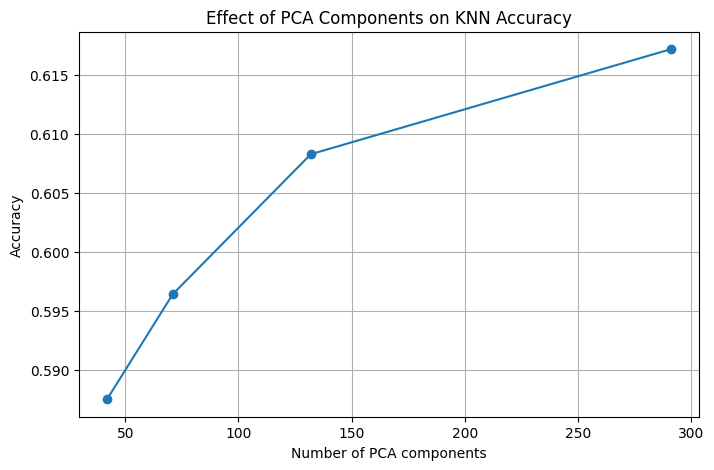

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
    results_df['PCs'],
    results_df['Accuracy'],
    marker='o'
)

plt.xlabel('Number of PCA components')
plt.ylabel('Accuracy')
plt.title('Effect of PCA Components on KNN Accuracy')
plt.grid(True)

plt.show()

# 6. K selection

In [ ]:
pca_value = 132
pca = PCA(n_components=pca_value)

X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

In [ ]:
k_values = range(1,31)

accuracy_list = []

for k in k_values:
  model = KNeighborsClassifier(n_neighbors=k)
  model.fit(X_train_pca,y_train)

  y_pred = model.predict(X_test_pca)

  acc = accuracy_score(y_test,y_pred)
  accuracy_list.append(acc)

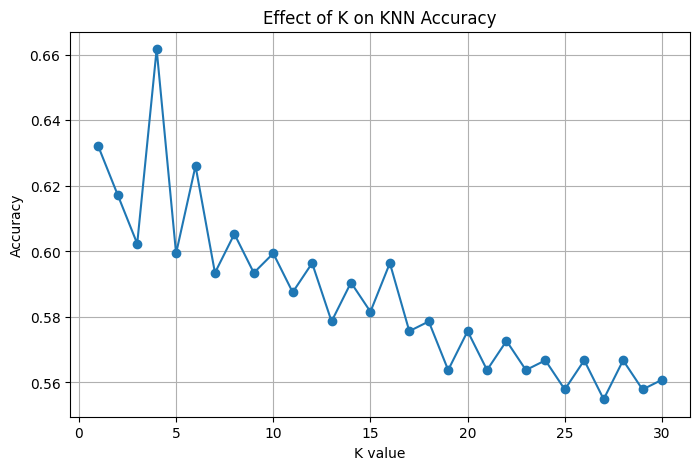

In [ ]:
plt.figure(figsize=(8,5))
plt.plot(
    k_values,
    accuracy_list,
    marker='o'
)

plt.xlabel('K value')
plt.ylabel('Accuracy')
plt.title('Effect of K on KNN Accuracy')
plt.grid(True)

plt.show()


In [ ]:
best_k = k_values[
    np.argmax(accuracy_list)
]

print(f"Best k value: {best_k}")

print("Best Accuracy:",
      max(accuracy_list)
      )

Best k value: 4
Best Accuracy: 0.6617210682492581



*   Distance Metric Comparison



In [ ]:
metrics = [
    'euclidean',
    'manhattan',
    'minkowski'
]


metrics_results = []

In [ ]:
for m in metrics:
  model = KNeighborsClassifier(n_neighbors=best_k,metric=m)
  model.fit(X_train_pca,y_train)

  y_pred = model.predict(X_test_pca)

  acc = accuracy_score(y_test,y_pred)
  metrics_results.append([m,acc])


metric_df = pd.DataFrame(metrics_results,columns=['Metric','Accuracy'])

print(metric_df)

      Metric  Accuracy
0  euclidean  0.661721
1  manhattan  0.563798
2  minkowski  0.661721


In [ ]:
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_pca,y_train)

y_pred = final_knn.predict(X_test_pca)


*   Evaluation Metrics



In [ ]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("Accuracy: ",accuracy)
print("Precision: ",precision)
print("Recall: ",recall)
print("F1 Score: ",f1)


Accuracy:  0.6617210682492581
Precision:  0.6008230452674898
Recall:  0.8957055214723927
F1 Score:  0.7192118226600985



*   Classification Report



In [ ]:
print(
    classification_report(
        y_test,
        y_pred
    )
)


              precision    recall  f1-score   support

           0       0.82      0.44      0.57       174
           1       0.60      0.90      0.72       163

    accuracy                           0.66       337
   macro avg       0.71      0.67      0.65       337
weighted avg       0.71      0.66      0.64       337



# 7. Performance of the current model


*   Confusion Matrix



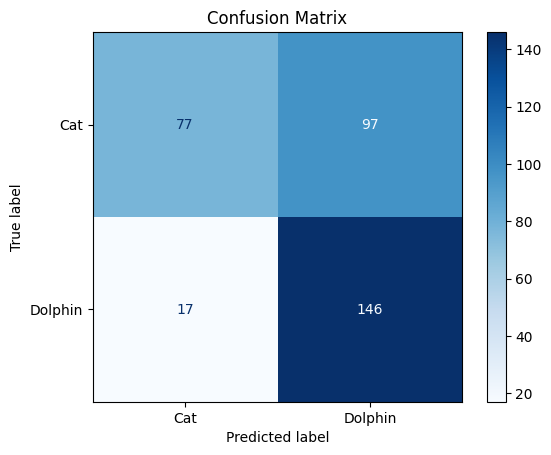

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

cm_display.plot(cmap='Blues')
plt.title("Confusion Matrix")
plt.show()

In [ ]:
results = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score'],
    'Value': [accuracy, precision, recall, f1]
})

print(results)

      Metric     Value
0   Accuracy  0.661721
1  Precision  0.600823
2     Recall  0.895706
3   F1 Score  0.719212


# 8. Conclusion:

The KNN model predicts class cat with 44.25% accuracy and class dolphin with 89.57% accuracy. The model performs considerably better at identifying the dolphin class images than the cat class images. This indicates that the dolphins are predicted more effectively.

There is a high proportion of misclassification with the cat class images.

The distance-weighted KNN approach resulted in an approximately 3.27 percentage-point decrease in overall accuracy compared with the original model. This suggests that distance weighting did not improve the model's performance under the current experimental settings.

The best-performing PCA configuration used 291 components, achieving the highest accuracy among the PCA configurations evaluated.


In [ ]:

# Calculate individual accuracy for each animal using the confusion matrix

individual_accuracy = cm.diagonal() / cm.sum(axis=1) * 100

for i, animal in enumerate(encoder.classes_):
    print(f"{animal} Prediction Accuracy: {individual_accuracy[i]:.2f}%")


Cat Prediction Accuracy: 44.25%
Dolphin Prediction Accuracy: 89.57%




---





---



-- Checking

 7b. Distance Weighted KNN approach

      Metric  Accuracy  Precision  Recall  F1 Score
0  euclidean    0.6202     0.5646  0.9387    0.7051
1  manhattan    0.5490     0.5183  0.9571    0.6724
2  minkowski    0.6202     0.5646  0.9387    0.7051


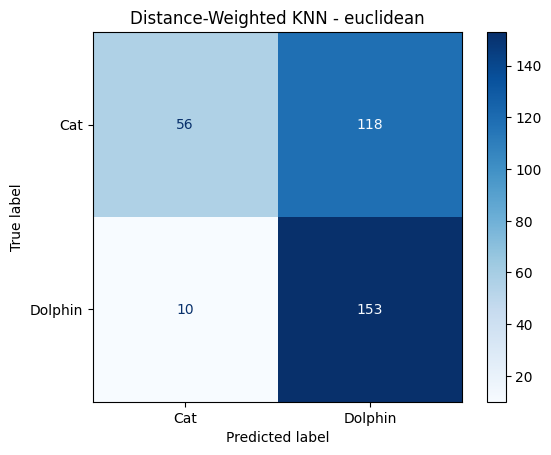

In [ ]:
weighted_results = []
weighted_predictions = {}

for m in metrics:
  model = KNeighborsClassifier(n_neighbors=best_k, metric=m, weights='distance')
  model.fit(X_train_pca,y_train)

  y_pred = model.predict(X_test_pca)

  weighted_predictions[m] = y_pred

  acc = accuracy_score(y_test, y_pred)
  prec = precision_score(y_test, y_pred, zero_division=0)
  rec = recall_score(y_test, y_pred, zero_division=0)
  f1 = f1_score(y_test, y_pred, zero_division=0)
  weighted_results.append([m, acc, prec, rec, f1])


weighted_metric_df = pd.DataFrame(weighted_results,columns=['Metric', 'Accuracy', 'Precision', 'Recall', 'F1 Score'])

print(weighted_metric_df.round(4))



best_metric = weighted_metric_df.loc[
    weighted_metric_df['Accuracy'].idxmax(), 'Metric'
]

y_pred_best = weighted_predictions[best_metric]

cm = confusion_matrix(y_test, y_pred_best)
cm = confusion_matrix(
    y_test,
    y_pred
)

cm_display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=encoder.classes_
)

cm_display.plot(cmap='Blues')
plt.title(f"Distance-Weighted KNN - {best_metric}")
plt.show()